/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.3252 - loss: 1.8059 - val_accuracy: 0.5262 - val_loss: 1.3194
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5404 - loss: 1.2854 - val_accuracy: 0.5994 - val_loss: 1.1391
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6015 - loss: 1.1264 - val_accuracy: 0.6448 - val_loss: 1.0212
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6503 - loss: 0.9941 - val_accuracy: 0.6268 - val_loss: 1.0598
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6756 - loss: 0.9240 - val_accuracy: 0.6854 - val_loss: 0.9110
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7040 - loss: 0.8480 - val_accuracy: 0.6888 - val_loss: 0.8999
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7286 - loss: 0.7857 - val_accuracy: 0.6866 - val_loss: 0.9044
Epoch 8/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7409 - loss: 0.7367 - val_accuracy: 0.

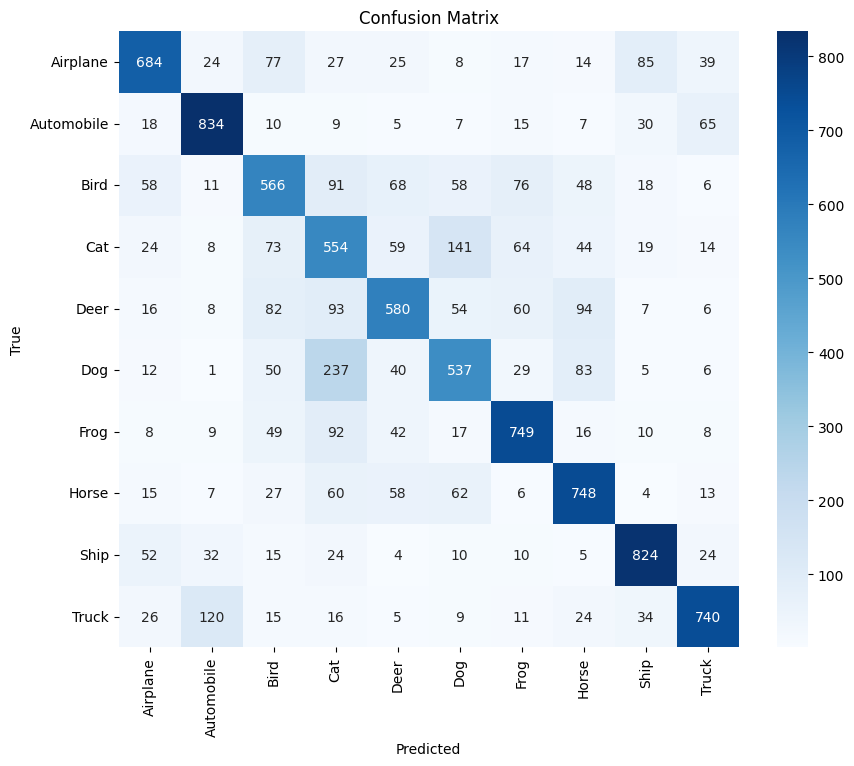

Classification Report:

              precision    recall  f1-score   support

    Airplane       0.75      0.68      0.72      1000
  Automobile       0.79      0.83      0.81      1000
        Bird       0.59      0.57      0.58      1000
         Cat       0.46      0.55      0.50      1000
        Deer       0.65      0.58      0.62      1000
         Dog       0.59      0.54      0.56      1000
        Frog       0.72      0.75      0.74      1000
       Horse       0.69      0.75      0.72      1000
        Ship       0.80      0.82      0.81      1000
       Truck       0.80      0.74      0.77      1000

    accuracy                           0.68     10000
   macro avg       0.68      0.68      0.68     10000
weighted avg       0.68      0.68      0.68     10000



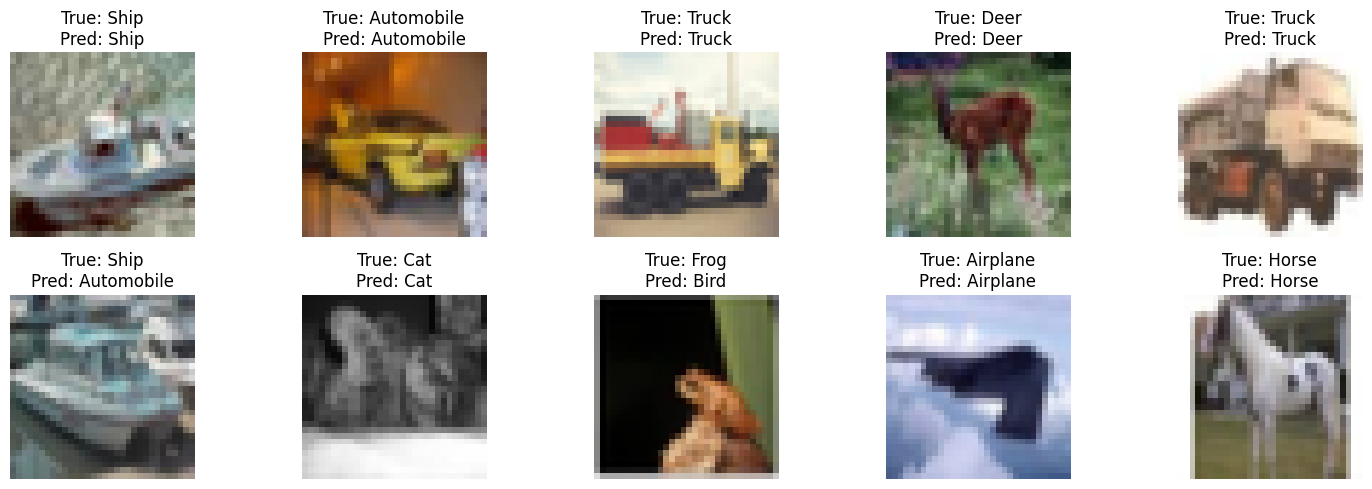

In [2]:
# Kaggle Notebook: CIFAR-10 CNN Classification

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# y values are shape (n,1), flatten them
y_train = y_train.flatten()
y_test = y_test.flatten()

# Class names
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# 2. Build CNN Model
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 3. Train
history = model.fit(x_train, y_train, epochs=40, validation_split=0.1, batch_size=64)

# 4. Save Model
model.save("cifar10_cnn.h5")

# 5. Evaluation
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Accuracy: {acc*100:.2f}%")

# Predictions
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# 6. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# 7. Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred_classes, target_names=class_names))

# 8. Test on 10 random samples
indices = random.sample(range(len(x_test)), 10)
plt.figure(figsize=(15,5))
for i, idx in enumerate(indices):
    img = x_test[idx]
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred_classes[idx]]

    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()
